# Prediksi Nilai Akhir Siswa
## Proyek Penggalian Data · Regresi Machine Learning
**Hanisah Aufa Khalidah** · **202310370311218**

Memprediksi nilai akhir Matematika (G3) setelah nilai periode G1 dan G2 tersedia. Analisis mencakup eksplorasi data, seleksi fitur, dan perbandingan model regresi. Korelasi menjelaskan hubungan statistik, bukan sebab-akibat.

## Dataset

Dataset yang digunakan adalah **Student Performance Dataset** dari UCI Machine Learning Repository.

Dataset ini berisi berbagai informasi akademik dan sosial siswa seperti nilai periode sebelumnya, jumlah ketidakhadiran, waktu belajar, latar belakang keluarga, dan atribut lainnya yang digunakan untuk memprediksi nilai akhir siswa.

Link dataset: https://archive.ics.uci.edu/dataset/320/student+performance

Target yang akan diprediksi adalah:

**G3** (Nilai akhir siswa, rentang 0 hingga 20)

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'data' / 'student-mat.csv').exists():
    raise FileNotFoundError('Jalankan notebook dari folder utama proyek yang berisi data/.')
ARTIFACTS = ROOT / 'artifacts'
ARTIFACTS.mkdir(exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
df = pd.read_csv(ROOT / 'data' / 'student-mat.csv', sep=';')
assert df.shape == (395, 33)
assert df['G3'].between(0, 20).all()
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


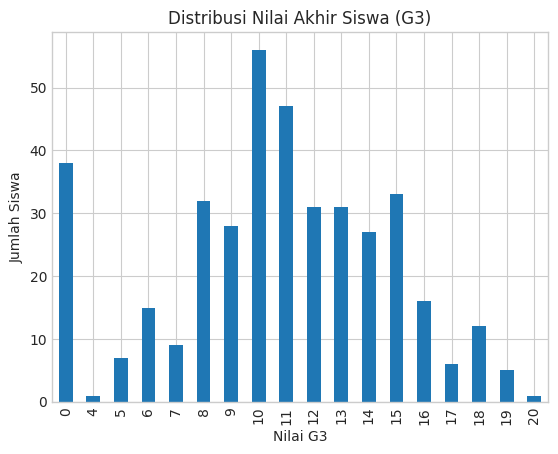

In [2]:
import matplotlib.pyplot as plt

df['G3'].value_counts().sort_index().plot(kind='bar')

plt.title('Distribusi Nilai Akhir Siswa (G3)')
plt.xlabel('Nilai G3')
plt.ylabel('Jumlah Siswa')

plt.show()

### Informasi Dataset

Melihat jumlah data, jumlah atribut, serta tipe data yang dimiliki dataset.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [4]:
print("Jumlah Baris dan Kolom:")
print(df.shape)

Jumlah Baris dan Kolom:
(395, 33)


## Data Cleaning

Tahap data cleaning dilakukan untuk memastikan data yang digunakan memiliki kualitas yang baik sebelum diproses lebih lanjut.

Pengecekan yang dilakukan meliputi:

- Missing Value
- Data Duplikat
- Atribut yang tidak diperlukan

### Pengecekan Missing Value

Missing value adalah kondisi di mana suatu kolom tidak memiliki nilai pada baris tertentu. Keberadaan missing value dapat memengaruhi kualitas model yang dibangun.

In [5]:
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [6]:
print('Total missing value:', int(df.isna().sum().sum()))

Total missing value: 0


### Pengecekan Data Duplikat

Data duplikat adalah baris data yang muncul lebih dari satu kali dengan nilai yang sama pada seluruh kolom. Data duplikat dapat memengaruhi hasil pelatihan model sehingga perlu diperiksa dan dihapus.

In [7]:
print("Jumlah Data Duplikat:", df.duplicated().sum())

Jumlah Data Duplikat: 0


### Pengecekan Outlier

Outlier adalah nilai ekstrem yang jauh berbeda dari sebagian besar data. Pengecekan dilakukan menggunakan visualisasi boxplot pada fitur-fitur numerik.

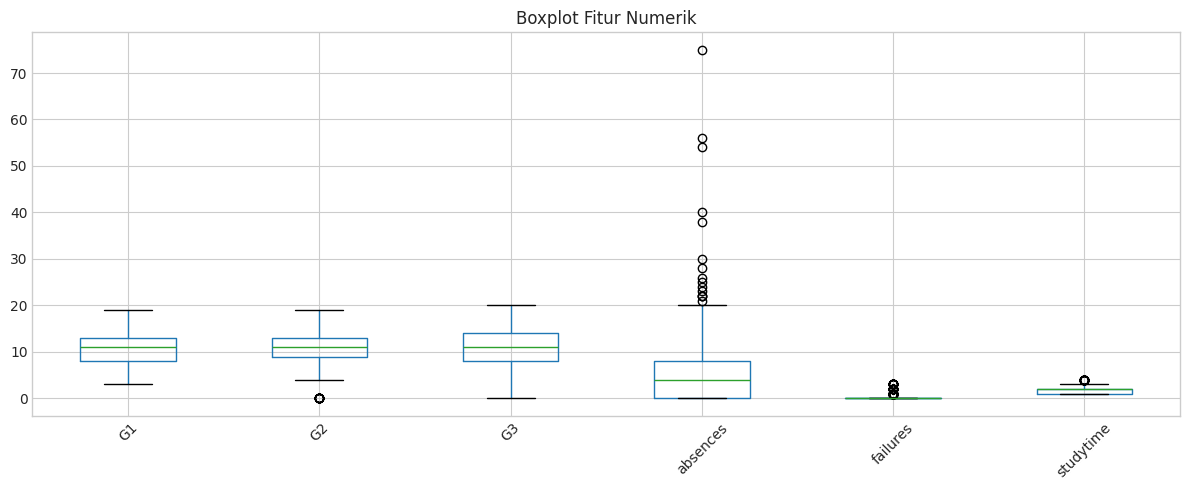

In [8]:
import matplotlib.pyplot as plt

num_cols = ['G1', 'G2', 'G3', 'absences', 'failures', 'studytime']

df[num_cols].boxplot(figsize=(12, 5))
plt.title('Boxplot Fitur Numerik')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Pembagian Data Sebelum Seleksi Fitur
Data dibagi 80:20 dengan random_state=42. Seluruh seleksi fitur dan fit scaler hanya menggunakan data training; data testing disimpan untuk evaluasi akhir.

Dataset tidak memiliki missing value atau duplikasi. Nilai ekstrem dipertahankan karena dapat merepresentasikan kondisi akademik yang valid.

In [9]:
from sklearn.model_selection import train_test_split
X = df.drop(columns='G3')
y = df['G3']
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
assert set(X_train_raw.index).isdisjoint(X_test_raw.index)
print(f'Training: {len(y_train)} siswa | Testing: {len(y_test)} siswa')

Training: 316 siswa | Testing: 79 siswa


## Seleksi Fitur Numerik
Korelasi Pearson dihitung pada training dengan ambang |r| ≥ 0,2 yang ditetapkan sebelum evaluasi. Atribut kategorikal tidak disertakan dalam eksperimen ini; label numerik arbitrer pada kategori nominal dapat membuat korelasi menyesatkan. Atribut numerik ordinal tetap diperlakukan sebagai angka.

Korelasi kecil tidak berarti suatu fitur tidak berguna pada model nonlinier. Ambang ini merupakan metode seleksi sederhana untuk eksperimen perkuliahan.

Fitur terpilih: ['G2', 'G1', 'Medu', 'failures']


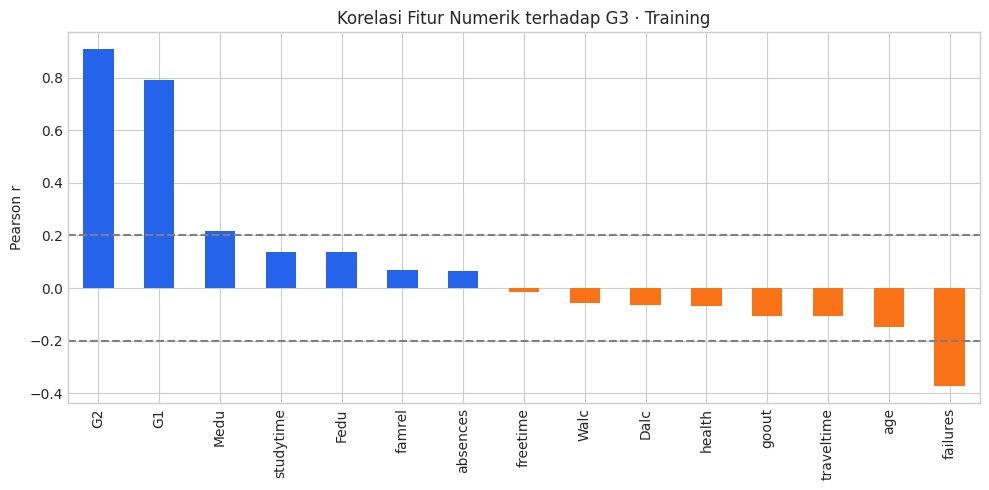

In [10]:
numeric_train = X_train_raw.select_dtypes(include='number')
corr_target = numeric_train.assign(G3=y_train).corr()['G3'].drop('G3').sort_values(ascending=False)
selected_features = corr_target[corr_target.abs() >= 0.2].index.tolist()
if not selected_features:
    raise ValueError('Tidak ada fitur yang memenuhi ambang korelasi.')
X_train = X_train_raw[selected_features].copy()
X_test = X_test_raw[selected_features].copy()
print('Fitur terpilih:', selected_features)
fig, ax = plt.subplots(figsize=(10, 5))
corr_target.plot.bar(ax=ax, color=['#2563eb' if v >= 0 else '#f97316' for v in corr_target])
ax.set(title='Korelasi Fitur Numerik terhadap G3 · Training', ylabel='Pearson r')
ax.axhline(0.2, color='gray', linestyle='--')
ax.axhline(-0.2, color='gray', linestyle='--')
plt.tight_layout()
fig.savefig(ARTIFACTS / 'feature_correlation.png', dpi=160)
plt.show()

## Pelatihan Model
- **Dummy Regressor:** pembanding sederhana yang memprediksi rata-rata G3 training.
- **Linear Regression:** StandardScaler di dalam Pipeline, di-fit hanya pada training.
- **Random Forest:** 300 pohon dengan random_state=42; scaling tidak diperlukan.

Tidak dilakukan tuning pada data testing. Prediksi mentah digunakan untuk evaluasi agar skor tidak berubah akibat pembulatan atau pembatasan ke 0–20.

In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

models = {
    'Dummy (Mean)': DummyRegressor(strategy='mean'),
    'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
    'Random Forest': RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=1),
}
predictions = {}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    rows.append({
        'Model': name,
        'RMSE': float(np.sqrt(mean_squared_error(y_test, predictions[name]))),
        'MAE': float(mean_absolute_error(y_test, predictions[name])),
        'R2': float(r2_score(y_test, predictions[name])),
    })
metrics = pd.DataFrame(rows).set_index('Model').sort_values('RMSE')
metrics.to_csv(ARTIFACTS / 'model_metrics.csv')
print(metrics.round(4).to_string())

                     RMSE     MAE      R2
Model                                    
Linear Regression  2.1299  1.2875  0.7788
Random Forest      2.2077  1.4435  0.7623
Dummy (Mean)       4.5502  3.6459 -0.0097


## Visualisasi Evaluasi
RMSE dan MAE yang lebih rendah menunjukkan galat lebih kecil; R² yang lebih tinggi menunjukkan kecocokan lebih baik pada data uji. R² bukan persentase akurasi.

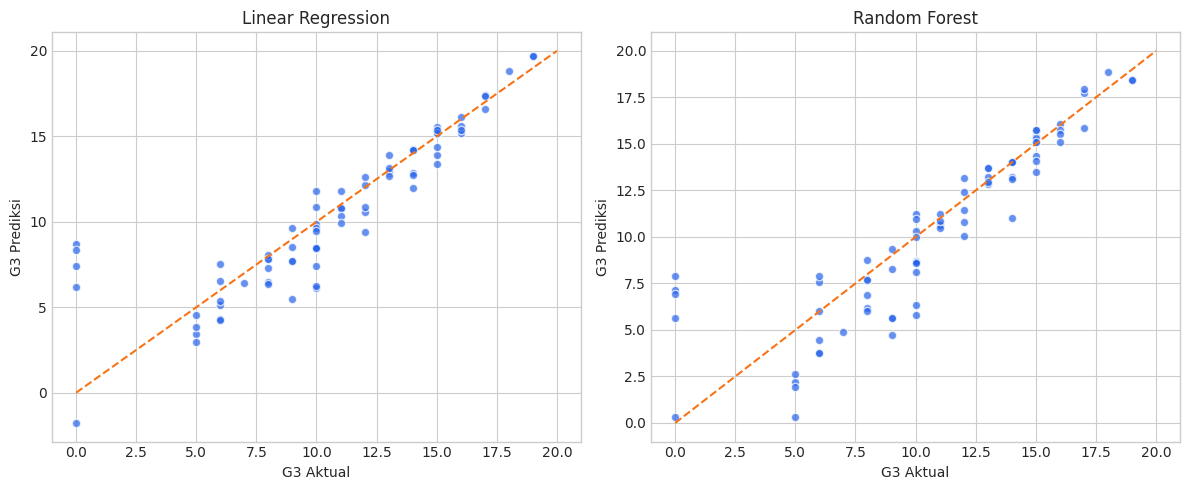

,student_index,G3_actual,Dummy (Mean),Linear Regression,Random Forest
0,78,10,10.325949,6.149353,5.795667
1,371,12,10.325949,12.142759,12.398333
2,248,5,10.325949,3.409712,2.180000
3,55,10,10.325949,8.409186,8.686288
4,390,9,10.325949,7.695321,5.655262
5,223,13,10.325949,12.885264,13.216226
6,42,18,10.325949,18.847601,18.843333
7,234,6,10.325949,6.547661,7.576444
8,316,0,10.325949,7.430200,5.664278
9,116,14,10.325949,12.832403,13.205438


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, ['Linear Regression', 'Random Forest']):
    ax.scatter(y_test, predictions[name], alpha=0.7, c='#2563eb', edgecolors='white')
    ax.plot([0, 20], [0, 20], '--', color='#f97316')
    ax.set(title=name, xlabel='G3 Aktual', ylabel='G3 Prediksi')
plt.tight_layout()
fig.savefig(ARTIFACTS / 'actual_vs_predicted.png', dpi=160)
plt.show()
comparison = pd.DataFrame({'student_index': y_test.index, 'G3_actual': y_test.to_numpy()})
for name, values in predictions.items():
    comparison[name] = values
comparison.to_csv(ARTIFACTS / 'test_predictions.csv', index=False)
comparison.head(10)

## Contoh Prediksi
Input mengikuti urutan fitur hasil seleksi dan makna atribut asli UCI. Contoh memakai baris testing yang sama untuk kedua model.

In [13]:
example = X_test.iloc[[0]]
print('Input:', example.iloc[0].to_dict())
print('G3 aktual:', y_test.iloc[0])
for name in ['Linear Regression', 'Random Forest']:
    print(f'{name}: {models[name].predict(example)[0]:.2f}')

Input: {'G2': 8, 'G1': 8, 'Medu': 2, 'failures': 3}
G3 aktual: 10
Linear Regression: 6.15
Random Forest: 5.80


## Interpretasi dan Batas Eksperimen
G1 dan G2 sudah tersedia pada saat prediksi, sehingga hasil berlaku untuk prediksi setelah periode kedua, bukan sebelum siswa mulai belajar. Hubungan fitur dengan nilai akhir tidak membuktikan sebab-akibat.

Evaluasi menggunakan satu holdout berisi 79 siswa dari dua sekolah di Portugal. Perbandingan pada split ini tidak membuktikan keunggulan umum suatu model. Nilai G3=0 tetap disertakan, dan belum dilakukan validasi lintas sekolah atau cross-validation.

Sumber: [UCI Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance), Paulo Cortez (2008), DOI: [10.24432/C5TG7T](https://doi.org/10.24432/C5TG7T). Dataset berlisensi [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).